In [76]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

In [77]:
# Function to be integrated
def f(x):
  return 1 / (1+x)

In [78]:
# Exact integral value
def exact_integral():
  return np.log(2)

In [79]:
# Gauss-Legendre Integration
def gauss_legendre(f, a, b, n):
  # Get Gauss-Legendre nodes and weights
  [nodes, weights] = np.polynomial.legendre.leggauss(n)
  # Change of interval
  t = 0.5 * (nodes+1) * (b-a) + a
  integral = 0.5 * (b-a) * np.sum(weights*f(t))
  return integral

In [80]:
# Define range and points
a, b = 0, 1
n_points = [1, 2, 3, 4]
exact_value = exact_integral()

In [81]:
# Perform integration and calculate errors
results = []
for n in n_points:
  approx = gauss_legendre(f, a, b, n)
  error = abs(exact_value - approx)
  results.append((n, approx, error))

In [82]:
# Create DataFrame for results
df = pd.DataFrame(results, columns=['Points', 'Approximation', 'Error'])
print('Gauss-Legendre Integration Results')
print(df.to_string(index=False))

Gauss-Legendre Integration Results
 Points  Approximation        Error
      1       0.666667 2.648051e-02
      2       0.692308 8.394883e-04
      3       0.693122 2.548744e-05
      4       0.693146 7.631145e-07


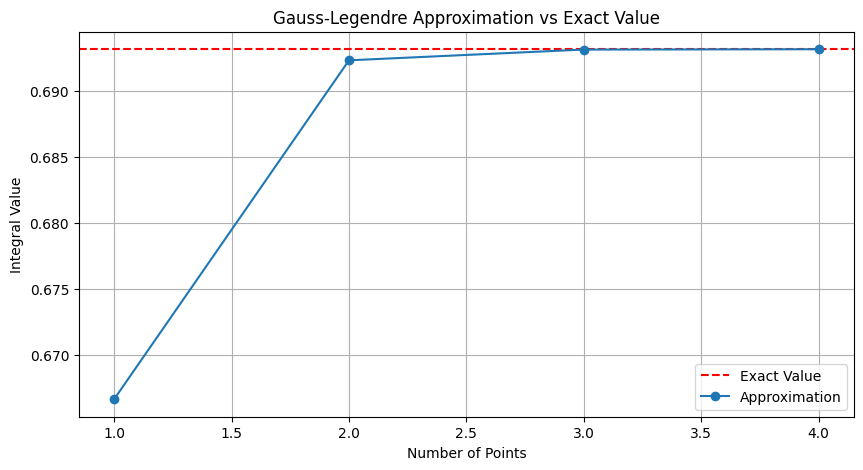

In [83]:
# Visualization of Approximation vs Exact Value
plt.figure(figsize=(10, 5))
plt.axhline(y=exact_value, color='r', linestyle='--', label='Exact Value')
plt.plot(df['Points'], df['Approximation'], marker='o', label='Approximation')
plt.xlabel('Number of Points')
plt.ylabel('Integral Value')
plt.title('Gauss-Legendre Approximation vs Exact Value')
plt.legend()
plt.grid(True)
plt.show()

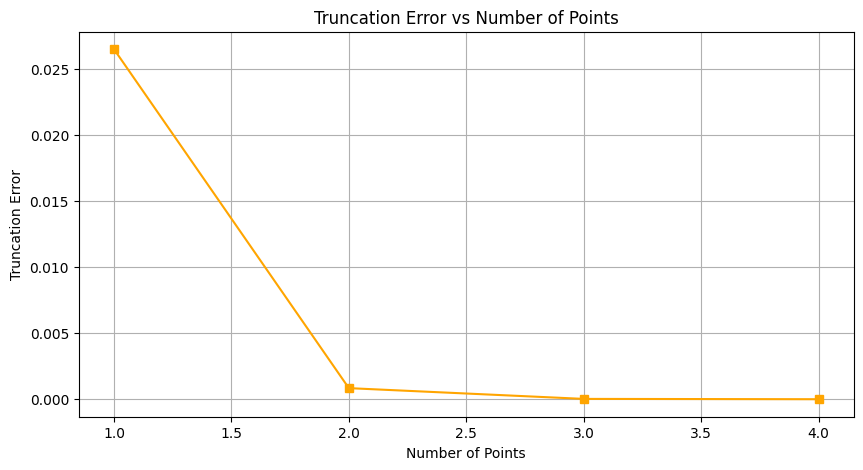

In [84]:
# Visualization of Truncation Error
plt.figure(figsize=(10, 5))
plt.plot(df['Points'], df['Error'], marker='s', color='orange')
plt.xlabel('Number of Points')
plt.ylabel('Truncation Error')
plt.title('Truncation Error vs Number of Points')
plt.grid(True)
plt.show()